# Caso de estudio Cyclistic: ¿cómo usan las bicicletas los miembros y los ciclistas casuales?

**Certificado Profesional de Google Data Analytics · Proyecto final (caso 1)**
Herramientas: **SQL (DuckDB)** para cargar, limpiar y agregar; **Python (pandas, matplotlib)** para revisar y graficar.
Datos: viajes de Divvy (Chicago), noviembre 2025 a octubre 2026.

El notebook sigue las fases del proceso de análisis: **Ask → Prepare → Process → Analyze → Share → Act**.

## 1. Ask: la tarea de negocio

La directora de Marketing, Lily Moreno, quiere convertir ciclistas casuales en miembros anuales, porque los miembros son más rentables.
La pregunta asignada es: **¿en qué se diferencia el uso de las bicicletas entre miembros anuales y ciclistas casuales?**

Partes interesadas: Lily Moreno (Marketing), el equipo ejecutivo de Cyclistic (aprueba la propuesta) y el equipo de análisis de Marketing.

## 2. Prepare: los datos

### 2.1 Configuración

In [1]:
import glob, os
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 160)

# Conexión a DuckDB (base de datos en un archivo local)
con = duckdb.connect('cyclistic.duckdb')
sql = lambda q: con.sql(q).df()   # ejecuta SQL y devuelve un DataFrame de pandas

# Colores consistentes en todos los gráficos
AZUL, GRIS = '#2a6fdb', '#b9b9ae'
COLORES = {'casual': AZUL, 'member': GRIS}
ETIQUETAS = {'casual': 'Casuales', 'member': 'Miembros'}
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'axes.titlesize': 12})
miles = mticker.FuncFormatter(lambda x, _: f'{x/1000:,.0f} mil'.replace(',', '.'))

### 2.2 Archivos

Son 12 archivos CSV mensuales descargados de [divvy-tripdata](https://divvy-tripdata.s3.amazonaws.com/index.html), publicados por Lyft Bikes and Scooters (Divvy) bajo su [licencia de datos](https://www.divvybikes.com/data-license-agreement).

Nota: el ZIP de enero de 2026 traía un CSV llamado `202501-divvy-tripdata.csv`. Las fechas internas son de enero de 2026, así que se renombró a `202601-divvy-tripdata.csv`. El archivo de octubre de 2025 se dejó fuera para trabajar con 12 meses exactos.

In [2]:
archivos = sorted(glob.glob('datos_originales/*.csv'))
pd.DataFrame({'archivo': [os.path.basename(a) for a in archivos],
              'tamaño_MB': [round(os.path.getsize(a) / 1e6, 1) for a in archivos]})

,archivo,tamaño_MB
0,202511-divvy-tripdata.csv,71.1
1,202512-divvy-tripdata.csv,28.3
2,202601-divvy-tripdata.csv,27.9
3,202602-divvy-tripdata.csv,41.2
4,202603-divvy-tripdata.csv,64.0
5,202604-divvy-tripdata.csv,89.8
6,202605-divvy-tripdata.csv,130.7
7,202606-divvy-tripdata.csv,152.6
8,202607-divvy-tripdata.csv,173.1
9,202608-divvy-tripdata.csv,172.8


In [3]:
# Filas y rango de fechas de cada archivo (verifica que cada archivo corresponde a su mes)
sql('''
SELECT regexp_extract(filename, '(\\d{6})', 1) AS archivo,
       COUNT(*) AS filas, MIN(started_at) AS primer_inicio, MAX(started_at) AS ultimo_inicio
FROM read_csv('datos_originales/*.csv', filename = true, union_by_name = true)
GROUP BY 1 ORDER BY 1
''')

,archivo,filas,primer_inicio,ultimo_inicio
0,202511,356628,2025-10-31 01:24:38.549,2025-11-30 23:51:43.800
1,202512,140534,2025-11-30 16:02:08.178,2025-12-31 23:53:24.274
2,202601,137787,2025-12-31 10:30:49.482,2026-01-31 23:56:54.069
3,202602,201450,2026-01-31 11:08:07.830,2026-02-28 23:57:54.093
4,202603,317037,2026-02-28 10:48:22.074,2026-03-31 23:55:56.848
5,202604,448252,2026-04-01 00:01:42.066,2026-04-30 23:58:56.151
6,202605,653704,2026-04-30 00:24:47.685,2026-05-31 23:57:08.778
7,202606,762550,2026-05-31 01:07:54.969,2026-06-30 23:58:47.113
8,202607,869051,2026-06-29 23:11:19.957,2026-07-31 23:58:05.898
9,202608,868191,2026-07-30 23:01:41.716,2026-08-31 23:55:36.979


### 2.3 Estructura y calidad de los datos en bruto

In [4]:
con.execute("CREATE OR REPLACE TABLE viajes_raw AS SELECT * FROM read_csv('datos_originales/*.csv', union_by_name = true)").fetchall()
sql('DESCRIBE viajes_raw')[['column_name', 'column_type']]

,column_name,column_type
0,ride_id,VARCHAR
1,rideable_type,VARCHAR
2,started_at,TIMESTAMP
3,ended_at,TIMESTAMP
4,start_station_name,VARCHAR
5,start_station_id,VARCHAR
6,end_station_name,VARCHAR
7,end_station_id,VARCHAR
8,start_lat,DOUBLE
9,start_lng,DOUBLE


In [5]:
sql('SELECT * FROM viajes_raw LIMIT 5')

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
0,E555D9F8E9C2F56B,electric_bike,2025-11-04 00:09:07.792,2025-11-04 00:15:04.661,None,None,None,None,41.94,-87.67,41.94,-87.67,casual
1,EAEBE70DBF015886,electric_bike,2025-11-04 14:32:09.067,2025-11-04 14:36:43.998,None,None,None,None,41.90,-87.64,41.91,-87.64,casual
2,A42F8404F804E56E,electric_bike,2025-11-04 12:20:48.215,2025-11-04 12:21:01.630,None,None,None,None,41.89,-87.63,41.89,-87.63,casual
3,E49D01E38A1E074E,electric_bike,2025-11-04 12:17:16.548,2025-11-04 12:17:51.527,None,None,None,None,41.89,-87.63,41.89,-87.63,casual
4,9308F609195D2414,electric_bike,2025-11-04 08:16:27.979,2025-11-04 08:21:02.780,None,None,None,None,41.89,-87.64,41.88,-87.64,casual


In [6]:
calidad = sql('''
SELECT COUNT(*)                                                   AS filas,
       COUNT(*) - COUNT(DISTINCT ride_id)                         AS ride_id_duplicados,
       COUNT(*) FILTER (WHERE start_station_name IS NULL)         AS sin_estacion_inicio,
       COUNT(*) FILTER (WHERE end_station_name IS NULL)           AS sin_estacion_fin,
       COUNT(*) FILTER (WHERE end_lat IS NULL)                    AS sin_coordenadas_fin,
       COUNT(*) FILTER (WHERE ended_at <= started_at)             AS duracion_cero_o_negativa,
       COUNT(*) FILTER (WHERE ended_at - started_at < INTERVAL 60 SECOND) AS menos_de_60_seg,
       COUNT(*) FILTER (WHERE ended_at - started_at > INTERVAL 24 HOUR)   AS mas_de_24_horas
FROM viajes_raw
''')
calidad.T.rename(columns={0: 'cantidad'})

,cantidad
filas,6294451
ride_id_duplicados,35
sin_estacion_inicio,1301806
sin_estacion_fin,1367998
sin_coordenadas_fin,5303
duracion_cero_o_negativa,29
menos_de_60_seg,159672
mas_de_24_horas,5155


In [7]:
# Valores posibles de las columnas categóricas
sql('SELECT rideable_type, member_casual, COUNT(*) AS viajes FROM viajes_raw GROUP BY ALL ORDER BY ALL')

,rideable_type,member_casual,viajes
0,classic_bike,casual,536098
1,classic_bike,member,1223157
2,electric_bike,casual,1703315
3,electric_bike,member,2831881


In [8]:
# Estaciones de prueba o bodega que no son viajes de clientes
sql('''
SELECT start_station_name, COUNT(*) AS viajes FROM viajes_raw
WHERE start_station_name ILIKE '%test%' OR start_station_name ILIKE '%warehouse%'
GROUP BY 1 ORDER BY 2 DESC
''')

,start_station_name,viajes
0,STAFF & VISITORS @ West Chicago Warehouse,17
1,Hastings Test Station,11


**¿Cumplen ROCCC?** Son confiables y originales (registros del propio operador, sin muestreo), actuales (los 12 meses más recientes) y citados (licencia pública).
Son *parcialmente* completos: faltan las estaciones en ~20% de los viajes y no hay información de los usuarios.

**Privacidad:** no hay datos personales. Por eso no se puede contar personas distintas ni saber si un casual vive en Chicago.

## 3. Process: limpieza y transformación

Toda la limpieza está en `sql/01_carga_y_limpieza.sql`. Reglas aplicadas:

1. Quitar `ride_id` duplicados (viajes repetidos en dos archivos mensuales).
2. Quedarse con viajes iniciados entre el 2025-11-01 y el 2026-10-31.
3. Quitar viajes de menos de 60 segundos (falsos inicios) y de más de 24 horas (bicicletas perdidas).
4. Quitar estaciones de prueba o bodega.
5. **Conservar** los viajes sin nombre de estación (casi todos son bicicletas eléctricas estacionadas fuera de una estación). Solo se excluyen del análisis por estación.

También se crean columnas nuevas: `ride_length_min`, `day_of_week` (1 = domingo … 7 = sábado), `hora`, `mes`, `tipo_dia`, `estacion_anio`, `distancia_km` (haversine) e `ida_y_vuelta`.

In [9]:
print(open('sql/01_carga_y_limpieza.sql').read())

-- =====================================================================
-- Caso de estudio Cyclistic (Google Data Analytics)
-- 01 - Carga y limpieza de datos
-- Motor: DuckDB (SQL estándar con algunas funciones propias de DuckDB)
-- Periodo: 12 meses, noviembre 2025 a octubre 2026
-- =====================================================================

-- 1) CARGA: se unen los 12 archivos mensuales en una sola tabla cruda.
--    union_by_name alinea las columnas por nombre aunque cambie el orden.
CREATE OR REPLACE TABLE viajes_raw AS
SELECT *
FROM read_csv('datos_originales/*.csv', union_by_name = true);

-- 2) LIMPIEZA Y TRANSFORMACIÓN
--    Reglas aplicadas (cada una se cuantifica en el notebook):
--    a) Duplicados: se conserva una sola fila por ride_id
--       (35 viajes aparecían en dos archivos mensuales consecutivos).
--    b) Ventana de análisis: solo viajes iniciados entre el
--       2025-11-01 y el 2026-10-31.
--    c) Duración: se descartan viajes de menos de 60 segund

In [10]:
# Ejecuta el script completo; muestra el resultado de la verificación final del script
con.execute(open('sql/01_carga_y_limpieza.sql').read()).df()

,viajes_limpios,ids_unicos,primer_viaje,ultimo_viaje,dur_min,dur_max
0,6129425,6129425,2025-11-01 00:00:08.613,2026-10-31 23:59:45.105,1.0,1439.95505


In [11]:
# Cuántas filas elimina cada regla (aplicadas en orden)
pasos = sql('''
WITH d AS (SELECT * FROM viajes_raw QUALIFY ROW_NUMBER() OVER (PARTITION BY ride_id ORDER BY started_at) = 1),
     w AS (SELECT * FROM d WHERE started_at >= '2025-11-01' AND started_at < '2026-11-01'),
     a AS (SELECT * FROM w WHERE ended_at - started_at >= INTERVAL 60 SECOND),
     b AS (SELECT * FROM a WHERE ended_at - started_at <= INTERVAL 24 HOUR)
SELECT 'Datos en bruto' AS paso, (SELECT COUNT(*) FROM viajes_raw) AS filas_restantes
UNION ALL SELECT '1. Sin duplicados', (SELECT COUNT(*) FROM d)
UNION ALL SELECT '2. Dentro de nov-2025 a oct-2026', (SELECT COUNT(*) FROM w)
UNION ALL SELECT '3a. Duración >= 60 segundos', (SELECT COUNT(*) FROM a)
UNION ALL SELECT '3b. Duración <= 24 horas', (SELECT COUNT(*) FROM b)
UNION ALL SELECT '4. Sin estaciones de prueba (tabla final)', (SELECT COUNT(*) FROM viajes)
''')
pasos['filas_eliminadas'] = (-pasos['filas_restantes'].diff()).fillna(0).astype(int)
total_elim = pasos['filas_restantes'].iloc[0] - pasos['filas_restantes'].iloc[-1]
print(f"Eliminadas en total: {total_elim:,} filas ({total_elim / pasos['filas_restantes'].iloc[0]:.1%})")
pasos

Eliminadas en total: 165,026 filas (2.6%)


,paso,filas_restantes,filas_eliminadas
0,Datos en bruto,6294451,0
1,1. Sin duplicados,6294416,35
2,2. Dentro de nov-2025 a oct-2026,6294288,128
3,3a. Duración >= 60 segundos,6134616,159672
4,3b. Duración <= 24 horas,6129488,5128
5,4. Sin estaciones de prueba (tabla final),6129425,63


In [12]:
# Verificación de la tabla limpia
sql('''
SELECT COUNT(*) AS viajes, COUNT(DISTINCT ride_id) AS ids_unicos,
       MIN(started_at) AS primer_viaje, MAX(started_at) AS ultimo_viaje,
       MIN(ride_length_min) AS dur_min, MAX(ride_length_min) AS dur_max,
       ROUND(100.0 * AVG((start_station_name IS NULL)::INT), 1) AS pct_sin_estacion
FROM viajes
''')

,viajes,ids_unicos,primer_viaje,ultimo_viaje,dur_min,dur_max,pct_sin_estacion
0,6129425,6129425,2025-11-01 00:00:08.613,2026-10-31 23:59:45.105,1.0,1439.95505,19.8


## 4. Analyze: miembros vs. casuales

### 4.1 Cálculos que pide el curso
Promedio y máximo de `ride_length`, y moda de `day_of_week`.

In [13]:
sql('''
SELECT ROUND(AVG(ride_length_min), 1) AS ride_length_promedio_min,
       ROUND(MAX(ride_length_min), 1) AS ride_length_max_min,
       MODE(day_of_week)              AS day_of_week_moda   -- 1 = domingo ... 7 = sábado
FROM viajes
''')

,ride_length_promedio_min,ride_length_max_min,day_of_week_moda
0,14.2,1440.0,7


In [14]:
# Lo mismo por tipo de usuario
sql('''
SELECT member_casual,
       ROUND(AVG(ride_length_min), 1) AS ride_length_promedio_min,
       ROUND(MAX(ride_length_min), 1) AS ride_length_max_min,
       MODE(day_of_week)              AS day_of_week_moda
FROM viajes GROUP BY 1 ORDER BY 1
''')

,member_casual,ride_length_promedio_min,ride_length_max_min,day_of_week_moda
0,casual,18.0,1440.0,7
1,member,12.1,1439.9,3


### 4.2 Tablas dinámicas (equivalentes a las del curso, hechas con pandas)

In [15]:
por_dia = sql('SELECT member_casual, day_of_week, COUNT(*) AS viajes, AVG(ride_length_min) AS duracion FROM viajes GROUP BY ALL')
dias = {1: 'Dom', 2: 'Lun', 3: 'Mar', 4: 'Mié', 5: 'Jue', 6: 'Vie', 7: 'Sáb'}
print('Promedio de ride_length (min) por día de la semana:')
display(por_dia.pivot(index='member_casual', columns='day_of_week', values='duracion').rename(columns=dias).round(1))
print('Cantidad de viajes por día de la semana:')
display(por_dia.pivot(index='member_casual', columns='day_of_week', values='viajes').rename(columns=dias))

Promedio de ride_length (min) por día de la semana:


day_of_week,Dom,Lun,Mar,Mié,Jue,Vie,Sáb
member_casual,,,,,,,
casual,20.7,18.1,15.7,15.1,15.7,17.6,20.4
member,13.2,11.8,11.7,11.6,11.6,12.0,13.4


Cantidad de viajes por día de la semana:


day_of_week,Dom,Lun,Mar,Mié,Jue,Vie,Sáb
member_casual,,,,,,,
casual,349541,249692,252157,249131,263344,334094,463929
member,421375,554879,647010,631452,613654,579957,519210


### 4.3 Resumen comparativo

In [16]:
resumen = sql('''
SELECT member_casual,
       COUNT(*) AS viajes,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct_viajes,
       ROUND(AVG(ride_length_min), 1)    AS duracion_promedio_min,
       ROUND(MEDIAN(ride_length_min), 1) AS duracion_mediana_min,
       ROUND(100.0 * AVG((ride_length_min > 30)::INT), 1) AS pct_mas_30_min,
       ROUND(MEDIAN(distancia_km), 2)    AS distancia_mediana_km,
       ROUND(100.0 * AVG(ida_y_vuelta::INT), 1) AS pct_ida_y_vuelta,
       ROUND(100.0 * AVG((tipo_dia = 'Fin de semana')::INT), 1) AS pct_fin_de_semana,
       ROUND(100.0 * AVG((rideable_type = 'electric_bike')::INT), 1) AS pct_electrica,
       ROUND(SUM(ride_length_min) / 60) AS horas_totales
FROM viajes GROUP BY 1 ORDER BY 1
''').set_index('member_casual')
resumen.T

member_casual,casual,member
viajes,2161888.00,3967537.00
pct_viajes,35.30,64.70
duracion_promedio_min,18.00,12.10
duracion_mediana_min,11.10,8.70
pct_mas_30_min,13.20,5.40
distancia_mediana_km,1.66,1.65
pct_ida_y_vuelta,5.60,1.70
pct_fin_de_semana,37.60,23.70
pct_electrica,75.40,69.20
horas_totales,649220.00,801585.00


In [17]:
r = resumen
print(f"Los casuales duran {r.loc['casual','duracion_promedio_min'] / r.loc['member','duracion_promedio_min'] - 1:.0%} más en promedio "
      f"y {r.loc['casual','duracion_mediana_min'] / r.loc['member','duracion_mediana_min'] - 1:.0%} más en mediana.")
print(f"Los casuales suman el {r.loc['casual','horas_totales'] / r['horas_totales'].sum():.0%} de las horas de uso "
      f"con el {r.loc['casual','pct_viajes']:.0f}% de los viajes.")

Los casuales duran 49% más en promedio y 28% más en mediana.
Los casuales suman el 45% de las horas de uso con el 35% de los viajes.


### 4.4 Cuándo: hora, día y mes

In [18]:
hora = sql('''
SELECT hora, member_casual,
       100.0 * COUNT(*) / SUM(COUNT(*)) OVER (PARTITION BY member_casual) AS pct
FROM viajes WHERE tipo_dia = 'Día laboral' GROUP BY 1, 2 ORDER BY 1
''').pivot(index='hora', columns='member_casual', values='pct')

mes = sql('''
SELECT mes, member_casual, COUNT(*) AS viajes FROM viajes GROUP BY 1, 2 ORDER BY 1
''').pivot(index='mes', columns='member_casual', values='viajes')
mes['pct_casuales'] = (100 * mes['casual'] / (mes['casual'] + mes['member'])).round(1)
ene, jul = pd.Timestamp('2026-01-01'), pd.Timestamp('2026-07-01')
print(f"Casuales: julio / enero = {mes.loc[jul,'casual'] / mes.loc[ene,'casual']:.1f} veces")
print(f"Miembros: julio / enero = {mes.loc[jul,'member'] / mes.loc[ene,'member']:.1f} veces")
mes

Casuales: julio / enero = 14.5 veces
Miembros: julio / enero = 4.6 veces


member_casual,casual,member,pct_casuales
mes,,,
2025-11-01,94719,251924,27.3
2025-12-01,27088,109371,19.9
2026-01-01,23878,109865,17.9
2026-02-01,40077,157240,20.3
2026-03-01,84812,223654,27.5
2026-04-01,127018,308460,29.2
2026-05-01,235873,399518,37.1
2026-06-01,297229,444151,40.1
2026-07-01,345551,500460,40.8


### 4.5 Dónde: estaciones

In [19]:
sql('''
SELECT member_casual, start_station_name, COUNT(*) AS viajes
FROM viajes WHERE start_station_name IS NOT NULL
GROUP BY 1, 2
QUALIFY ROW_NUMBER() OVER (PARTITION BY member_casual ORDER BY COUNT(*) DESC) <= 10
ORDER BY 1, 3 DESC
''')

,member_casual,start_station_name,viajes
0,casual,Navy Pier,49971
1,casual,DuSable Lake Shore Dr & Monroe St,28234
2,casual,Michigan Ave & Oak St,20702
3,casual,Millennium Park,17011
4,casual,DuSable Lake Shore Dr & North Blvd,16750
5,casual,Shedd Aquarium,16192
6,casual,Theater on the Lake,14981
7,casual,Dusable Harbor,13769
8,casual,Field Museum,10368
9,casual,Montrose Harbor,10156


### 4.6 El segmento con más potencial: casuales en horario punta de días laborales

In [20]:
sql('''
SELECT CASE WHEN hora BETWEEN 7 AND 9 THEN 'Mañana (7-9 h)' ELSE 'Tarde (16-18 h)' END AS franja,
       COUNT(*) AS viajes_casuales,
       ROUND(MEDIAN(ride_length_min), 1) AS duracion_mediana_min
FROM viajes
WHERE member_casual = 'casual' AND tipo_dia = 'Día laboral'
  AND (hora BETWEEN 7 AND 9 OR hora BETWEEN 16 AND 18)
GROUP BY 1 ORDER BY 1
''')

,franja,viajes_casuales,duracion_mediana_min
0,Mañana (7-9 h),148629,7.9
1,Tarde (16-18 h),393108,10.9


In [21]:
# Estaciones de donde salen los casuales en la punta de la mañana: coinciden con las de los miembros
sql('''
SELECT start_station_name, COUNT(*) AS viajes
FROM viajes
WHERE member_casual = 'casual' AND tipo_dia = 'Día laboral' AND hora BETWEEN 7 AND 9
  AND start_station_name IS NOT NULL
GROUP BY 1 ORDER BY 2 DESC LIMIT 10
''')

,start_station_name,viajes
0,Navy Pier,1277
1,Canal St & Madison St,1197
2,Clinton St & Jackson Blvd,1117
3,Wells St & Hubbard St,1064
4,Michigan Ave & Oak St,1049
5,Clinton St & Washington Blvd 2,997
6,Kingsbury St & Kinzie St 1,930
7,Wells St & Huron St,878
8,Clinton St & Madison St,863
9,Clark St & Elm St,853


## 5. Share: visualizaciones

En todos los gráficos, los casuales van en azul y los miembros en gris.

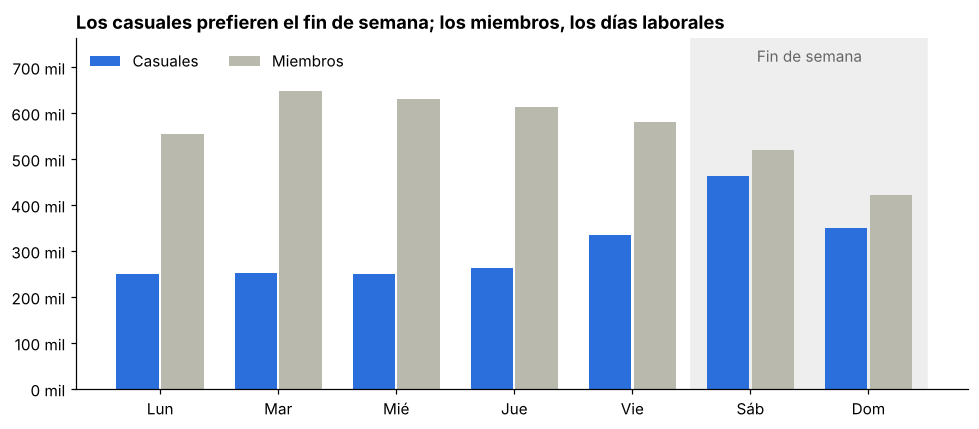

In [22]:
fig, ax = plt.subplots(figsize=(9, 4))
orden = [2, 3, 4, 5, 6, 7, 1]   # lunes a domingo
piv = por_dia.pivot(index='day_of_week', columns='member_casual', values='viajes').loc[orden]
x = range(len(orden))
for k, t in enumerate(['casual', 'member']):
    ax.bar([i + (k - 0.5) * 0.38 for i in x], piv[t], width=0.36, color=COLORES[t], label=ETIQUETAS[t])
ax.axvspan(4.5, 6.5, color='#eeeeee', zorder=0)
ax.text(5.5, piv.values.max() * 1.1, 'Fin de semana', ha='center', color='#666')
ax.set_xticks(list(x), [dias[d] for d in orden])
ax.yaxis.set_major_formatter(miles)
ax.set_title('Los casuales prefieren el fin de semana; los miembros, los días laborales', loc='left')
ax.set_ylim(0, piv.values.max() * 1.18)
ax.legend(frameon=False, ncol=2, loc='upper left')
plt.tight_layout(); plt.savefig('graficos/1_viajes_por_dia.png', dpi=150); plt.show()

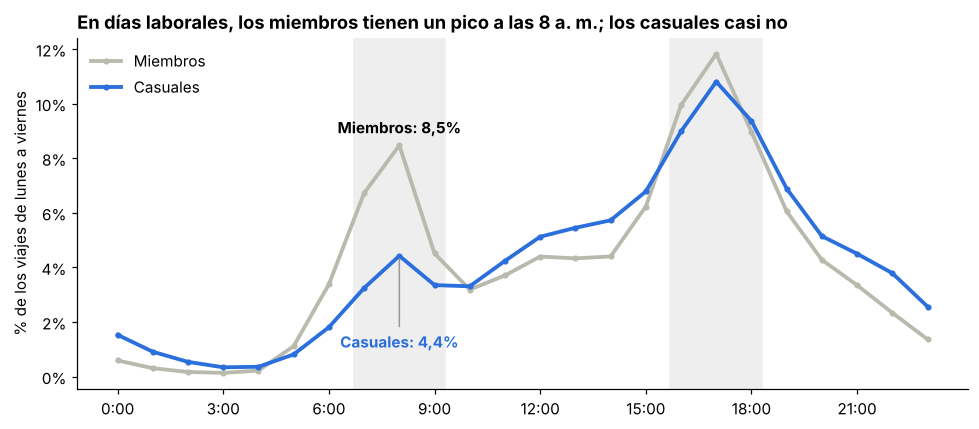

In [23]:
fig, ax = plt.subplots(figsize=(9, 4))
for t in ['member', 'casual']:
    ax.plot(hora.index, hora[t], marker='o', ms=3, lw=2.5, color=COLORES[t], label=ETIQUETAS[t])
for a, b in [(7, 9), (16, 18)]:
    ax.axvspan(a - 0.3, b + 0.3, color='#eeeeee', zorder=0)
ax.annotate(f"Miembros: {hora.loc[8,'member']:.1f}%".replace(".", ","), (8, hora.loc[8, 'member']), xytext=(0, 8), textcoords='offset points', ha='center', weight='bold')
ax.annotate(f"Casuales: {hora.loc[8,'casual']:.1f}%".replace(".", ","), (8, hora.loc[8, 'casual']), xytext=(0, -60), textcoords='offset points', ha='center', weight='bold', color=AZUL,
            arrowprops=dict(arrowstyle='-', color='#999'))
ax.set_xticks(range(0, 24, 3), [f'{h}:00' for h in range(0, 24, 3)])
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_title('En días laborales, los miembros tienen un pico a las 8 a. m.; los casuales casi no', loc='left')
ax.set_ylabel('% de los viajes de lunes a viernes')
ax.legend(frameon=False, loc='upper left')
plt.tight_layout(); plt.savefig('graficos/2_viajes_por_hora.png', dpi=150); plt.show()

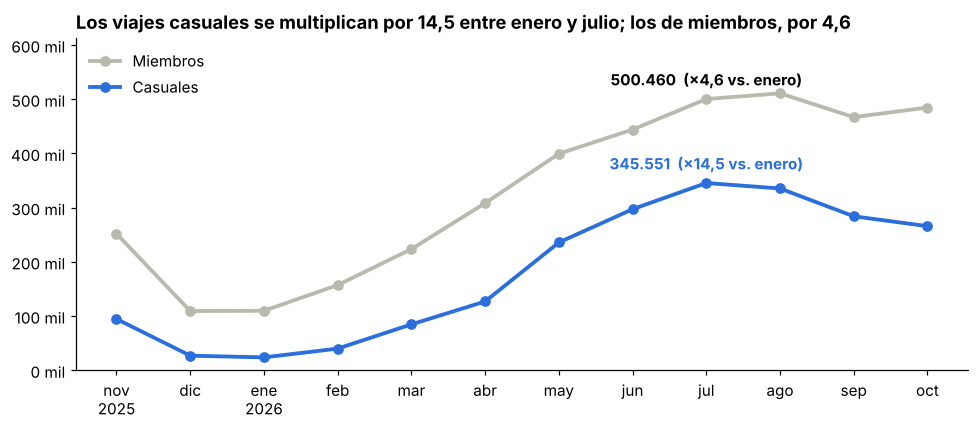

In [24]:
fig, ax = plt.subplots(figsize=(9, 4))
MESES = ['ene', 'feb', 'mar', 'abr', 'may', 'jun', 'jul', 'ago', 'sep', 'oct', 'nov', 'dic']
etiquetas_mes = [f'{MESES[m.month - 1]}\n{m.year}' if m.month in (11, 1) else MESES[m.month - 1] for m in mes.index]
for t in ['member', 'casual']:
    ax.plot(range(len(mes)), mes[t], marker='o', lw=2.5, color=COLORES[t], label=ETIQUETAS[t])
for t in ['member', 'casual']:
    i_ene, i_jul = list(mes.index).index(ene), list(mes.index).index(jul)
    ax.annotate(f"{mes.loc[jul, t]:,}".replace(',', '.') + "  (×" + f"{mes.loc[jul, t] / mes.loc[ene, t]:.1f}".replace(".", ",") + " vs. enero)",
                (i_jul, mes.loc[jul, t]), xytext=(0, 9), textcoords='offset points', ha='center', weight='bold',
                color=AZUL if t == 'casual' else 'black')
ax.set_xticks(range(len(mes)), etiquetas_mes)
ax.set_ylim(0, mes[['casual', 'member']].values.max() * 1.2)
ax.yaxis.set_major_formatter(miles)
ax.set_title('Los viajes casuales se multiplican por 14,5 entre enero y julio; los de miembros, por 4,6', loc='left')
ax.legend(frameon=False, loc='upper left')
plt.tight_layout(); plt.savefig('graficos/3_viajes_por_mes.png', dpi=150); plt.show()

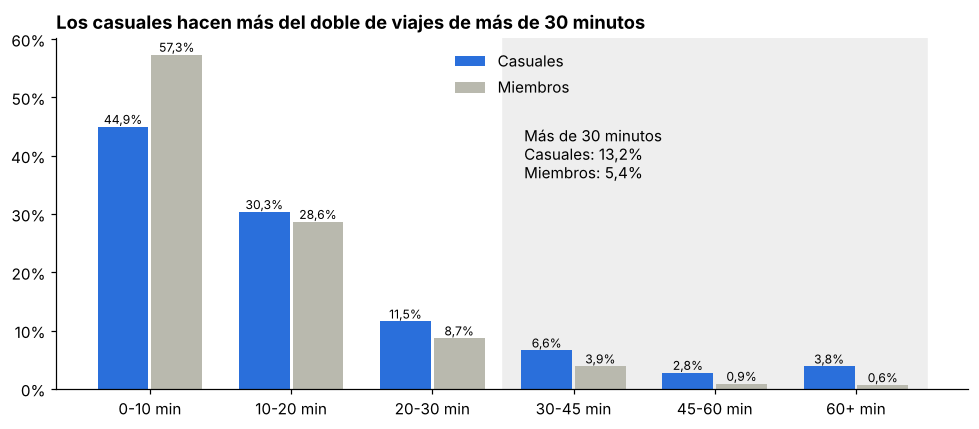

In [25]:
dur = sql('''
SELECT member_casual,
       CASE WHEN ride_length_min < 10 THEN '0-10' WHEN ride_length_min < 20 THEN '10-20'
            WHEN ride_length_min < 30 THEN '20-30' WHEN ride_length_min < 45 THEN '30-45'
            WHEN ride_length_min < 60 THEN '45-60' ELSE '60+' END AS rango,
       100.0 * COUNT(*) / SUM(COUNT(*)) OVER (PARTITION BY member_casual) AS pct
FROM viajes GROUP BY 1, 2
''').pivot(index='rango', columns='member_casual', values='pct').loc[['0-10', '10-20', '20-30', '30-45', '45-60', '60+']]

fig, ax = plt.subplots(figsize=(9, 4))
x = range(len(dur))
for k, t in enumerate(['casual', 'member']):
    barras = ax.bar([i + (k - 0.5) * 0.38 for i in x], dur[t], width=0.36, color=COLORES[t], label=ETIQUETAS[t])
    ax.bar_label(barras, labels=[f'{v:.1f}%'.replace('.', ',') for v in dur[t]], fontsize=8)
ax.axvspan(2.5, 5.5, color='#eeeeee', zorder=0)
largos = dur.loc[['30-45', '45-60', '60+']].sum()
ax.text(2.65, 45, f"Más de 30 minutos\nCasuales: {largos['casual']:.1f}%\nMiembros: {largos['member']:.1f}%".replace(".", ","), va='top')
ax.set_xticks(list(x), [f'{r} min' for r in dur.index])
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_title('Los casuales hacen más del doble de viajes de más de 30 minutos', loc='left')
ax.legend(frameon=False, loc='upper center')
plt.tight_layout(); plt.savefig('graficos/4_duracion.png', dpi=150); plt.show()

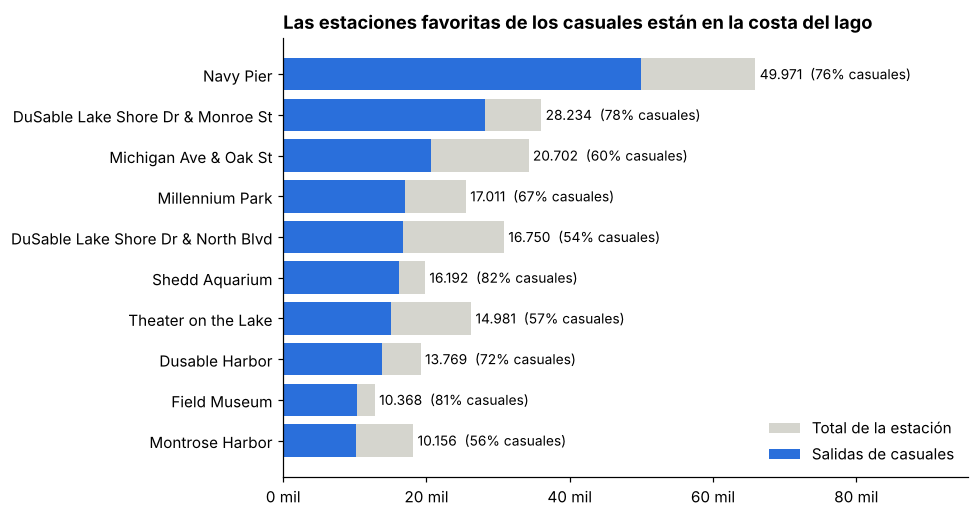

In [26]:
est = sql('''
SELECT start_station_name AS estacion,
       COUNT(*) FILTER (WHERE member_casual = 'casual') AS casuales, COUNT(*) AS total
FROM viajes WHERE start_station_name IS NOT NULL
GROUP BY 1 ORDER BY casuales DESC LIMIT 10
''').iloc[::-1]
est['pct_casuales'] = 100 * est['casuales'] / est['total']

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(est['estacion'], est['total'], color=GRIS, alpha=0.6, label='Total de la estación')
ax.barh(est['estacion'], est['casuales'], color=AZUL, label='Salidas de casuales')
for i, r in enumerate(est.itertuples()):
    ax.text(r.total + 600, i, f"{r.casuales:,}".replace(',', '.') + f"  ({r.pct_casuales:.0f}% casuales)", va='center', fontsize=9)
ax.xaxis.set_major_formatter(miles)
ax.set_xlim(0, est['total'].max() * 1.45)
ax.set_title('Las estaciones favoritas de los casuales están en la costa del lago', loc='left')
ax.legend(frameon=False, loc='lower right')
plt.tight_layout(); plt.savefig('graficos/5_estaciones_casuales.png', dpi=150); plt.show()

## 6. Act: conclusiones y recomendaciones

**Respuesta a la pregunta:** los miembros usan Cyclistic como transporte diario: viajes cortos, de lunes a viernes, con picos a las 8 y a las 17 h y estable durante el año.
Los casuales la usan sobre todo para pasear: viajes un 49% más largos, más fines de semana, muy concentrados en verano y en estaciones turísticas junto al lago.

**Tres recomendaciones:**

1. **Convertir primero a los casuales que se trasladan al trabajo.** Hay 148.629 viajes casuales en la punta de la mañana, cortos y desde las mismas estaciones de oficinas que usan los miembros. Mostrarles el ahorro de una membresía después de varios viajes en horario punta.
2. **Campaña de primavera y verano en las estaciones del lago** (Navy Pier, DuSable Lake Shore Dr & Monroe St, Millennium Park, Shedd Aquarium), lanzada en abril y mayo, antes del peak de julio. Evaluar una membresía de temporada o de fin de semana como puerta de entrada.
3. **Mostrar el valor de la membresía en los viajes largos.** El 13,2% de los viajes casuales dura más de 30 minutos (5,4% en miembros): al terminar esos viajes, mostrar en la app cuánto costarían como miembro.

**Limitaciones:** el análisis cuenta viajes, no personas (no hay ID de usuario); la distancia es en línea recta; el 20% de los viajes no tiene estación.

In [27]:
# Exportar el archivo resumen para análisis posteriores (paso 8 del enunciado)
os.makedirs('resumen', exist_ok=True)
resumen.to_csv('resumen/resumen_miembros_vs_casuales.csv')
por_dia.to_csv('resumen/viajes_por_dia.csv', index=False)
mes.to_csv('resumen/viajes_por_mes.csv')
hora.to_csv('resumen/viajes_por_hora_laborales.csv')
print('Archivos exportados:', sorted(os.listdir('resumen')))

Archivos exportados: ['resumen_miembros_vs_casuales.csv', 'viajes_por_dia.csv', 'viajes_por_hora_laborales.csv', 'viajes_por_mes.csv']
